# Auditoría de identidades: un split perfecto sobre el grafo equivocado

## Pregunta y utilidad
¿Cero componentes declarados cortados garantiza independencia de identidades adjudicadas? No: esta extensión del programa29–30 construye el diagnóstico que faltaba. La hipótesis de suficiencia se refuta con **un contraejemplo**; el umbral, escenarios y semillas están en config_graph31.json antes de interpretar resultados. No es descubrimiento algorítmico ni evaluación empírica de ML.

Comando completo: `bash run_graph_audit.sh`. Python3.12 y dependencias fijadas. Datos sintéticos28 filas; no hay etiquetas predictivas. La verdad se usa **después** de congelar la asignación, salvo el oráculo privilegiado explícito.

In [1]:
import json, csv
from pathlib import Path
from IPython.display import display, Image
from src.graph_audit import audit_graph
from src.graph_experiment import corpus
from src.balancing import balanced_split
from src.splitter import Record
config=json.loads(Path('config_graph31.json').read_text())
print(config['hypothesis'], '\nUmbral:',config['threshold'])

zero declared component cuts does not suffice for zero adjudicated leakage 
Umbral: one explicit counterexample with declared_cuts=0 and adjudicated_cuts>0 refutes universal sufficiency


## Marco teórico y derivación
Sea $O$ la partición observada y $T$ la adjudicada sobre el mismo universo $V$, $|V|=n$. La clausura transitiva de vínculos explícitos produce cada partición. No compara aristas directas: un enlace transitivo correcto cuenta como co-pertenencia.

La métrica original29 es $C_O=\sum_{o\in O}1\{o\cap A\ne\varnothing,\ o\cap A^c\ne\varnothing\}$, número de componentes observados cortados por entrenamiento $A$.30 minimiza $d=||A|-n/2|$ sujeto a $C_O=0$.

Propuesta de auditoría (métricas conocidas): sustituir el universo de evaluación por $T$, sin cambiar la asignación, y medir $C_T$ y $E_T=\sum_{t\in T}|t|1\{t\cap A\ne\varnothing,t\cap A^c\ne\varnothing\}$. $E_T$ son **filas pertenecientes a identidades repartidas**, no número de pares ni pérdida predictiva. $0\le E_T\le n$.

Para medir la calidad de la partición: $n_{ot}=|o\cap t|$, $TP=\sum_{o,t}\binom{n_{ot}}2$. Cada par co-observado pertenece a una celda de contingencia si además es co-verdadero; por ello $FP=\sum_o\binom{|o|}2-TP$, $FN=\sum_t\binom{|t|}2-TP$, $TN=\binom n2-TP-FP-FN$. Todos son conteos enteros de **pares no ordenados**, diferentes de sklearn que cuenta pares ordenados. Unidades: filas, componentes, pares, nanosegundos y bytes; no probabilidades estimadas.

Si cada componente verdadero está contenido en uno observado (solo sobre-unión), $C_O=0\Rightarrow C_T=0$: cualquier subconjunto de un conjunto asignado indivisiblemente queda en ese mismo lado. A cambio disminuye el conjunto de masas factibles; el óptimo de balance no puede mejorar. Si faltan enlaces, no vale la inclusión y falla la implicación. Estas propiedades se deducen de inclusión de conjuntos; no generalizan fuera de un snapshot adjudicado completo.

In [2]:
truth=[Record(str(i),('person',)) for i in range(4)]
observed=[Record(str(i),(f'fragment{i//2}',)) for i in range(4)]
assignment=balanced_split(observed)
a=audit_graph(observed,truth,assignment)
print('Asignación:',assignment,'\nAuditoría:',a)
assert (a.declared_cuts,a.adjudicated_cuts,a.exposed_rows)==(0,1,4)
assert (a.true_positive_pairs,a.false_negative_pairs)==(2,4)

Asignación: {'0': 'train', '1': 'train', '2': 'test', '3': 'test'} 
Auditoría: GraphAudit(rows=4, declared_cuts=0, adjudicated_cuts=1, exposed_rows=4, true_positive_pairs=2, false_positive_pairs=0, false_negative_pairs=4, true_negative_pairs=0)


## Datos y experimentos
Cuatro identidades verdaderas de tamaños4/6/8/10, fragmentación alterna dentro de cada identidad, sobre-unión de las primeras3, o mezcla de ambos.12 semillas permutan IDs dentro del mismo diseño y aleatorizan baseline por grupos; **no son12 poblaciones**. Se conservan144 filas CSV (4regímenes×12semillas×3políticas). count30 y balanced30 reciben exactamente el mismo grafo observado; truth_oracle recibe verdad privilegiada, sirve como límite diagnóstico y puede cortar el grafo declarado. No es competidor desplegable. No hacemos inferencia de intervalos poblacionales.

In [3]:
rows=list(csv.DictReader(Path('results/graph31/raw.csv').open()))
summary=json.loads(Path('results/graph31/summary.json').read_text())
for name,s in summary.items():
    print(f"{name:25} fuga={s['runs_with_true_leakage']:2}/{s['runs']} expuestas={s['mean_exposed_rows']:6.2f} desv={s['mean_deviation_rows']:5.2f}")
assert len(rows)==144
assert summary['missing:balanced30']['runs_with_true_leakage']==12
assert summary['accurate:balanced30']['runs_with_true_leakage']==0

accurate:count30          fuga= 0/12 expuestas=  0.00 desv= 3.17
accurate:balanced30       fuga= 0/12 expuestas=  0.00 desv= 0.00
accurate:truth_oracle     fuga= 0/12 expuestas=  0.00 desv= 0.00
missing:count30           fuga=10/12 expuestas= 14.00 desv= 1.50
missing:balanced30        fuga=12/12 expuestas=  8.00 desv= 0.00
missing:truth_oracle      fuga= 0/12 expuestas=  0.00 desv= 0.00
overmerged:count30        fuga= 0/12 expuestas=  0.00 desv= 4.00
overmerged:balanced30     fuga= 0/12 expuestas=  0.00 desv= 4.00
overmerged:truth_oracle   fuga= 0/12 expuestas=  0.00 desv= 0.00
mixed:count30             fuga= 8/12 expuestas= 18.67 desv= 1.33
mixed:balanced30          fuga=12/12 expuestas= 28.00 desv= 0.00
mixed:truth_oracle        fuga= 0/12 expuestas=  0.00 desv= 0.00


## Comparación de mecanismos
La figura separa exposición de identidades (riesgo de evaluación) del balance de filas (restricción de tamaño). Un balance exacto no es certificado de independencia. Colores y marcadores identifican políticas; las líneas conectan escenarios categóricos para facilitar comparación, sin trayectoria temporal.

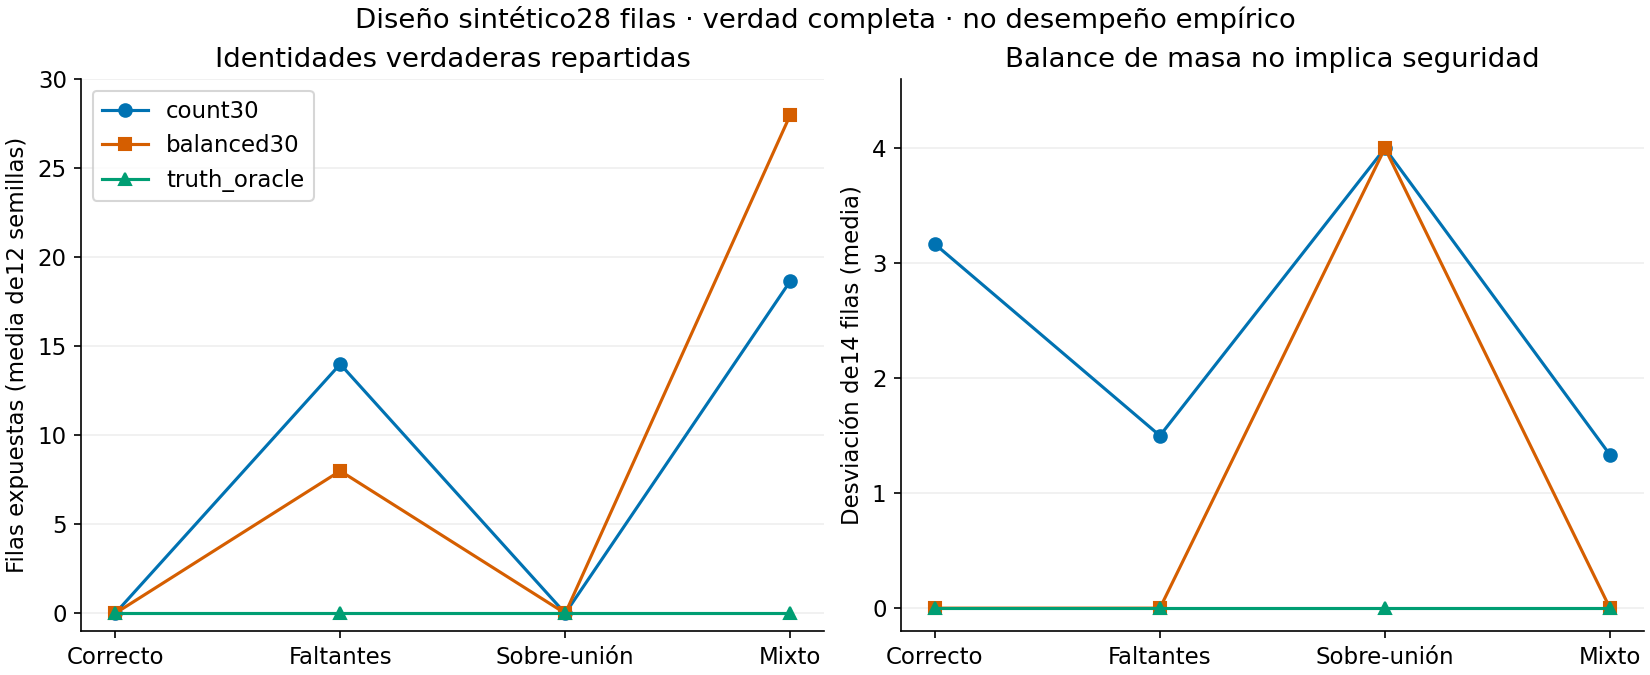

In [4]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
regimes=config['regimes']; labels=['Correcto','Faltantes','Sobre-unión','Mixto']
fig,axs=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for method,color,marker in [('count30','#0072B2','o'),('balanced30','#D55E00','s'),('truth_oracle','#009E73','^')]:
    for ax,metric in zip(axs,['mean_exposed_rows','mean_deviation_rows']):
        ax.plot(labels,[summary[f'{r}:{method}'][metric] for r in regimes],label=method,color=color,marker=marker)
        ax.grid(axis='y',alpha=.2)
axs[0].set(ylabel='Filas expuestas (media de12 semillas)',title='Identidades verdaderas repartidas',ylim=(-1,30))
axs[1].set(ylabel='Desviación de14 filas (media)',title='Balance de masa no implica seguridad',ylim=(-.2,4.6))
axs[0].legend(loc='upper left')
fig.suptitle('Diseño sintético28 filas · verdad completa · no desempeño empírico')
fig.savefig('results/graph31/mechanism.png',dpi=150)
display(Image(filename='results/graph31/mechanism.png'))
plt.close(fig)

## Ablations y fallos
Retirar la auditoría adjudicada devuelve0 cortes declarados en todas las asignaciones factibles count/DP y oculta exposiciones reales. Corregir todo el grafo (oráculo) elimina exposición; sobre-unir también la elimina en estos diseños, pero la desviación aumenta de0 a4 filas. En mixto el DP logra balance exacto y expone las28 filas: resultado negativo conservado, sin ajuste posterior de parámetros.

La auditoría requiere adjudicación completa y coherente. Si falta una fila, se abstiene con error; **no rellena verdad a partir del mismo grafo**. La verdad suministrada puede estar equivocada; no hay identificación de identidad latente a partir del split.

In [5]:
obs,truth=corpus(0,'missing')
try:
    audit_graph(obs,truth[:-1],balanced_split(obs))
except ValueError as e:
    print('Abstención explícita:',e)
else:
    raise AssertionError('Adjudicación incompleta aceptada')
for r in ['accurate','missing','overmerged','mixed']:
    o,t=corpus(0,r); a=audit_graph(o,t,balanced_split(o))
    print(r,'TP/FP/FN/TN=',(a.true_positive_pairs,a.false_positive_pairs,a.false_negative_pairs,a.true_negative_pairs))
    assert sum([a.true_positive_pairs,a.false_positive_pairs,a.false_negative_pairs,a.true_negative_pairs])==378

Abstención explícita: nonempty identical observed/adjudicated record IDs required
accurate TP/FP/FN/TN= (94, 0, 0, 284)
missing TP/FP/FN/TN= (40, 0, 54, 284)
overmerged TP/FP/FN/TN= (94, 104, 0, 180)
mixed TP/FP/FN/TN= (40, 52, 54, 232)


## Sensibilidad de coste y límites
Se mide splitter y auditoría por separado, con perf_counter_ns y tracemalloc; instalación/I/O/notebook excluidos. La siguiente figura varía28–28000 filas para el auditor, manteniendo8 fragmentos: no evalúa la escalabilidad del DP. El núcleo usa clausuras con ordenación, coste $O(n\log n+L)$ para $L$ incidencias de identidad, memoria $O(n+L)$ más enteros. No materializa $\binom n2$ pares. Tiempos de una pasada por tamaño son ilustrativos y sensibles al host; no benchmark universal.

[
  {
    "rows": 28,
    "audit_ns": 718120,
    "peak_bytes": 4936
  },
  {
    "rows": 280,
    "audit_ns": 4927756,
    "peak_bytes": 52888
  },
  {
    "rows": 2800,
    "audit_ns": 48625464,
    "peak_bytes": 574104
  },
  {
    "rows": 28000,
    "audit_ns": 595494906,
    "peak_bytes": 4982096
  }
]


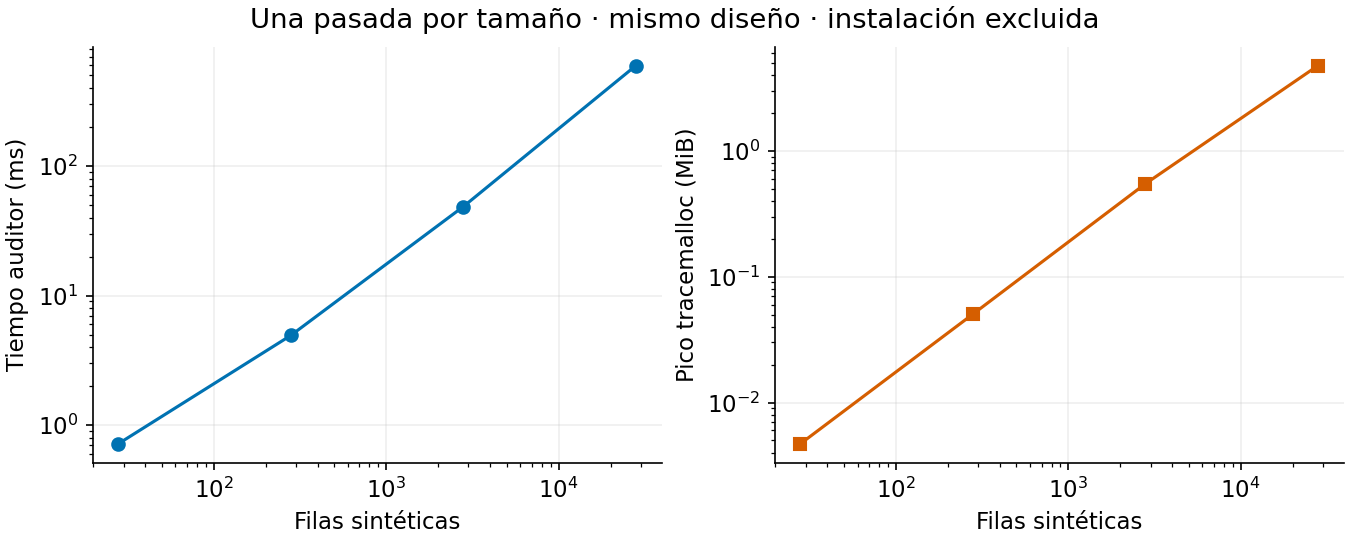

In [6]:
scale=json.loads(Path('results/graph31/scale.json').read_text())
print(json.dumps(scale,indent=2))
fig,axs=plt.subplots(1,2,figsize=(9,3.6),layout='constrained')
axs[0].loglog([s['rows'] for s in scale],[s['audit_ns']/1e6 for s in scale],marker='o',color='#0072B2')
axs[1].loglog([s['rows'] for s in scale],[s['peak_bytes']/1024**2 for s in scale],marker='s',color='#D55E00')
for ax in axs: ax.set_xlabel('Filas sintéticas'); ax.grid(alpha=.2)
axs[0].set_ylabel('Tiempo auditor (ms)');axs[1].set_ylabel('Pico tracemalloc (MiB)')
fig.suptitle('Una pasada por tamaño · mismo diseño · instalación excluida')
fig.savefig('results/graph31/cost.png',dpi=150)
display(Image(filename='results/graph31/cost.png'));plt.close(fig)

## Discusión calculada y continuidad
Sabemos que la garantía29–30 es condicional a la partición suministrada. Construimos un auditor modular verificable con oráculo de pares independiente y abstención. Ahora podemos distinguir errores de fragmentación y sobre-unión y cuantificar filas expuestas sin entrenar un predictor. No sabemos prevalencia de errores reales, impacto en AUC ni causalidad; tampoco resolvimos enlaces temporales o adjudicación parcial.

Clasificación: **auditoría y adaptación de ingeniería**, no método nuevo ni contribución científica original acreditada. Madurez local experimental ejecutada con tests; revisión independiente y publicación se registran aparte en informe consolidado. No validado en negocio ni operacional. Continuar con contrato de adjudicación real disponible antes del corte temporal; ajustar si falta cobertura; cerrar cualquier claim de independencia real basado solo en el grafo observado.

Fuentes: Kapoor/Narayanan2023 (DOI10.1016/j.patter.2023.100804); documentación primaria sklearn GroupShuffleSplit, pair_confusion_matrix, precision_recall_fscore_support; NetworkX connected_components. Matriz prior_art31.md y entradas audit31 en referencias.bib. Ejecución real secuencial IPython en proceso, captura de figuras; no kernel aislado Jupyter.